In [61]:
## Binary Tree Assignment 

In [62]:
import statistics

In [63]:
class Node:
    def __init__(self, key):
        self.key = key
        self.left = None
        self.right = None


In [64]:
class BinarySearchTree:
    def __init__(self):
        self.root = None
        
    def insert(self, key):
        self.root = self._insert(self.root, key)
        
    def _insert(self, node, key):
        if node is None:
            return Node(key)

        if key < node.key:
            node.left = self._insert(node.left, key)
        elif key > node.key:
            node.right = self._insert(node.right, key)

        return node

    def _height(self, node):
        if node is None:
            return -1   

        left_height = self._height(node.left)
        right_height = self._height(node.right)
        height = 1 + max(left_height, right_height)
        
        return height
         
    def height(self):
        return self._height(self.root)

    def _collect_depths(self, node, current_depth, depths):
        if node is None:
            return

        depths.append(current_depth)

        self._collect_depths(node.left, current_depth + 1, depths)
        self._collect_depths(node.right, current_depth + 1, depths)

    def get_depths(self):
        depths = []
        self._collect_depths(self.root, 0, depths)
        return depths

    def average_depth(self):
        depths = self.get_depths()

    # Accounts for empty tree (dividing by zero?)
        if depths == []:
            return 0
        else: 
            average_depth = sum(depths) / len(depths) 
            return average_depth
            
    def average_depth_search(self):
        depths = self.get_depths()
        
        if depths == []:
            return 1
        else: 
            return (sum(depths) + len(depths)) / len(depths)


    def balanced_insi(self, keys, left, right, middle_vals_list):
        if left > right:
            return 

        mid = (left + right) // 2
        middle_vals_list.append(keys[mid]) 
        self.balanced_insi(keys, left, mid - 1, middle_vals_list)
        self.balanced_insi(keys, mid + 1, right, middle_vals_list)   
        
    def get_balanced_order(self, N):
        keys = list(range(1, N + 1))
        order_list = []
        self.balanced_insi(keys, 0, len(keys) - 1, order_list)
        return(order_list) 

In [65]:
## Testing Phases 

In [66]:
bst = BinarySearchTree()

for key in [50, 30, 70, 20, 40, 60, 80, 35, 45]:
    bst.insert(key)

print(bst.height())         
print(bst.get_depths())     
print(bst.average_depth())  
print(bst.average_depth_search())  

3
[0, 1, 2, 2, 3, 3, 1, 2, 2]
1.7777777777777777
2.7777777777777777


In [67]:
bst = BinarySearchTree()

numbers = list(range(1, 11))

for key in numbers:
    bst.insert(key)

print(bst.height())         
print(bst.get_depths())     
print(bst.average_depth())  
print(bst.average_depth_search()) 

9
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
4.5
5.5


In [68]:
keys = list(range(1, 8))
order = []

bst = BinarySearchTree()
bst.balanced_insi(keys, 0, len(keys) - 1, order)

print(order)

[4, 2, 1, 3, 6, 5, 7]


In [69]:
bst_balanced = BinarySearchTree()

for key in order:
    bst_balanced.insert(key)

print(bst_balanced.height())
print(bst.get_balanced_order(7))
print(bst_balanced.get_depths())
print(bst_balanced.average_depth_search())

2
[4, 2, 1, 3, 6, 5, 7]
[0, 1, 2, 2, 1, 2, 2]
2.4285714285714284


In [70]:
bst = BinarySearchTree()
print(bst.get_balanced_order(7))

[4, 2, 1, 3, 6, 5, 7]


In [71]:
## Pt 2 - Experimentation 

In [72]:
## Testing 

In [73]:
N = 100
keys = list(range(1, N + 1))

bst_ascending = BinarySearchTree()
for key in keys:
    bst_ascending.insert(key)

print("Height:", bst_ascending.height())
print("Average depth:", bst_ascending.average_depth())
print("Average comparisons:", bst_ascending.average_depth_search())

Height: 99
Average depth: 49.5
Average comparisons: 50.5


In [74]:
balanced_order = bst_balanced.get_balanced_order(N)

for key in balanced_order:
    bst_balanced.insert(key)

print("Height:", bst_balanced.height())
print("Average depth:", bst_balanced.average_depth())
print("Average comparisons:", bst_balanced.average_depth_search())

Height: 9
Average depth: 7.3
Average comparisons: 8.3


In [75]:
import random

keys = list(range(1, N + 1))
random.shuffle(keys)
bst_random = BinarySearchTree()

for key in keys:
    bst_random.insert(key)

print("Height:", bst_random.height())
print("Average depth:", bst_random.average_depth())
print("Average comparisons:", bst_random.average_depth_search())

Height: 14
Average depth: 7.24
Average comparisons: 8.24


In [76]:
# ascending, balanced, random

In [85]:
random_results = []

for N in sizes:
    for seed in range(1, 11):
        random.seed(seed)
        keys = list(range(1, N + 1))
        random.shuffle(keys)

        bst_random = BinarySearchTree()
        for key in keys:
            bst_random.insert(key)

        random_results.append({
            "N": N,
            "seed": seed,
            "height": bst_random.height(),
            "average_depth": bst_random.average_depth(),
            "average_comparisons": bst_random.average_depth_search()
        })

print("Total trials:", len(random_results))

Total trials: 40


In [77]:
import random
random_results = []

sizes = [100, 500, 1000, 2000]

for N in sizes:
    for seed in range(1, 11):
        random.seed(seed)
        keys = list(range(1, N + 1))
        random.shuffle(keys)

    bst_random = BinarySearchTree()
    for key in keys:
        bst_random.insert(key)

    trial_result = {
        "N": N,
        "seed": seed,
        "height": bst_random.height(),
        "average_depth": bst_random.average_depth(),
        "average_comparisons": bst_random.average_depth_search()
    }

    random_results.append(trial_result)

for result in random_results:
    print(result)

{'N': 100, 'seed': 10, 'height': 12, 'average_depth': 6.06, 'average_comparisons': 7.06}
{'N': 500, 'seed': 10, 'height': 21, 'average_depth': 10.514, 'average_comparisons': 11.514}
{'N': 1000, 'seed': 10, 'height': 20, 'average_depth': 10.633, 'average_comparisons': 11.633}
{'N': 2000, 'seed': 10, 'height': 22, 'average_depth': 11.937, 'average_comparisons': 12.937}


In [86]:
print(len(random_results))

40


In [79]:
ascending_results = []
balanced_results = []

sizes = [100, 500, 1000, 2000]

for N in sizes:
    keys = list(range(1, N + 1))

    # Ascending insertion
    bst_ascending = BinarySearchTree()
    for key in keys:
        bst_ascending.insert(key)

    ascending_results.append({
        "N": N,
        "height": bst_ascending.height(),
        "average_depth": bst_ascending.average_depth(),
        "average_comparisons": bst_ascending.average_depth_search()
    })

    # Balanced insertion
    bst_balanced = BinarySearchTree()
    balanced_order = bst_balanced.get_balanced_order(N)

    for key in balanced_order:
        bst_balanced.insert(key)

    balanced_results.append({
        "N": N,
        "height": bst_balanced.height(),
        "average_depth": bst_balanced.average_depth(),
        "average_comparisons": bst_balanced.average_depth_search()
    })

In [80]:
print("Ascending:")
for result in ascending_results:
    print(result)

print("\nBalanced:")
for result in balanced_results:
    print(result)


Ascending:
{'N': 100, 'height': 99, 'average_depth': 49.5, 'average_comparisons': 50.5}
{'N': 500, 'height': 499, 'average_depth': 249.5, 'average_comparisons': 250.5}
{'N': 1000, 'height': 999, 'average_depth': 499.5, 'average_comparisons': 500.5}
{'N': 2000, 'height': 1999, 'average_depth': 999.5, 'average_comparisons': 1000.5}

Balanced:
{'N': 100, 'height': 6, 'average_depth': 4.8, 'average_comparisons': 5.8}
{'N': 500, 'height': 8, 'average_depth': 6.996, 'average_comparisons': 7.996}
{'N': 1000, 'height': 9, 'average_depth': 7.987, 'average_comparisons': 8.987}
{'N': 2000, 'height': 10, 'average_depth': 8.982, 'average_comparisons': 9.982}


In [87]:
import statistics

random_summary = []

for N in sizes:
    trials = [result for result in random_results if result["N"] == N]

    random_summary.append({
        "N": N,
        "mean_height": statistics.mean(
            result["height"] for result in trials
        ),
        "mean_average_comparisons": statistics.mean(
            result["average_comparisons"] for result in trials
        )
    })

for result in random_summary:
    print(result)

{'N': 100, 'mean_height': 12.3, 'mean_average_comparisons': 7.5729999999999995}
{'N': 500, 'mean_height': 19.3, 'mean_average_comparisons': 10.6636}
{'N': 1000, 'mean_height': 21.4, 'mean_average_comparisons': 12.103}
{'N': 2000, 'mean_height': 22.9, 'mean_average_comparisons': 13.0198}


In [82]:
# Graphs 

In [83]:
import matplotlib.pyplot as plt

In [88]:
# 4, 4, 40, 4
print(len(ascending_results)) 
print(len(balanced_results))   
print(len(random_results))     
print(len(random_summary))     

4
4
40
4


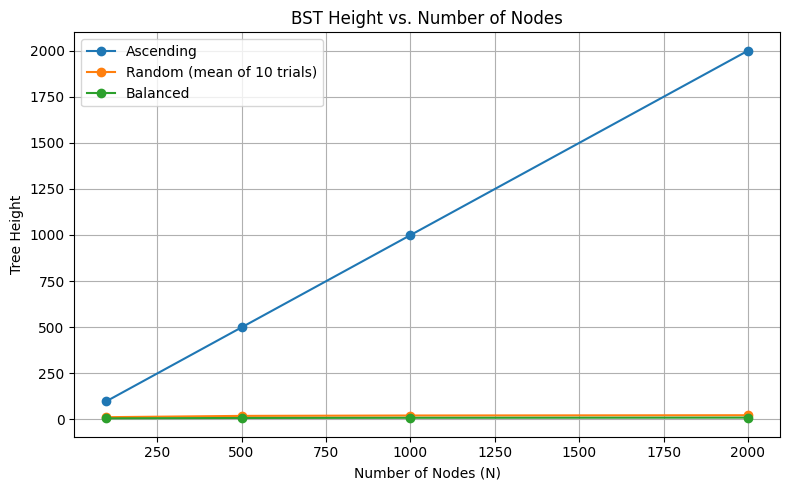

In [89]:
# Extract values for the x-axis
N_values = [result["N"] for result in ascending_results]

# Extract heights for each strategy
ascending_heights = [result["height"] for result in ascending_results]
balanced_heights = [result["height"] for result in balanced_results]
random_heights = [result["mean_height"] for result in random_summary]

# Plot
plt.figure(figsize=(8, 5))

plt.plot(N_values, ascending_heights, marker="o", label="Ascending")
plt.plot(N_values, random_heights, marker="o", label="Random (mean of 10 trials)")
plt.plot(N_values, balanced_heights, marker="o", label="Balanced")

plt.xlabel("Number of Nodes (N)")
plt.ylabel("Tree Height")
plt.title("BST Height vs. Number of Nodes")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

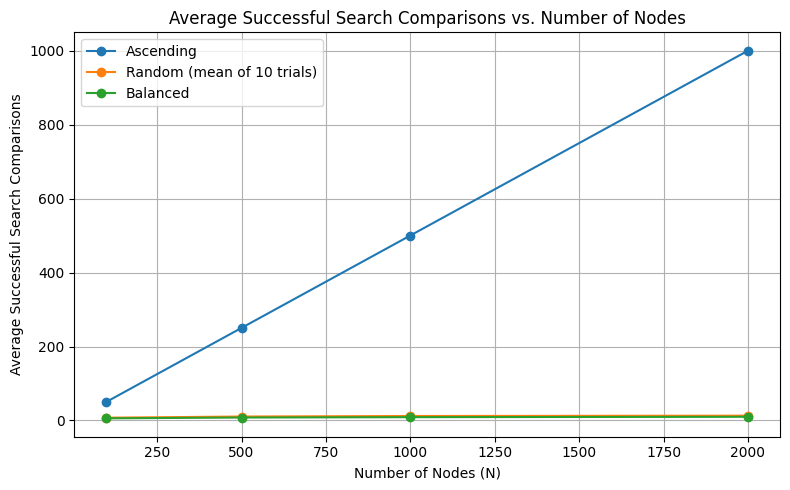

In [90]:
# Extract average successful search comparisons
ascending_comparisons = [
    result["average_comparisons"] for result in ascending_results]

balanced_comparisons = [
    result["average_comparisons"] for result in balanced_results]

random_comparisons = [
    result["mean_average_comparisons"] for result in random_summary]

# Plot
plt.figure(figsize=(8, 5))

plt.plot(N_values, ascending_comparisons, marker="o", label="Ascending")
plt.plot(N_values, random_comparisons, marker="o", label="Random (mean of 10 trials)")
plt.plot(N_values, balanced_comparisons, marker="o", label="Balanced")

plt.xlabel("Number of Nodes (N)")
plt.ylabel("Average Successful Search Comparisons")
plt.title("Average Successful Search Comparisons vs. Number of Nodes")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [91]:
import random
import sys

# Allow recursion for the ascending tree with 1000 nodes
sys.setrecursionlimit(5000)

N = 1000

# 1. Ascending BST
bst_ascending_1000 = BinarySearchTree()

for key in range(1, N + 1):
    bst_ascending_1000.insert(key)

ascending_depths = bst_ascending_1000.get_depths()


# 2. Random BST 
random_seed = 1
random.seed(random_seed)

random_keys = list(range(1, N + 1))
random.shuffle(random_keys)

bst_random_1000 = BinarySearchTree()

for key in random_keys:
    bst_random_1000.insert(key)

random_depths = bst_random_1000.get_depths()


# 3. Balanced BST
bst_balanced_1000 = BinarySearchTree()
balanced_order = bst_balanced_1000.get_balanced_order(N)

for key in balanced_order:
    bst_balanced_1000.insert(key)

balanced_depths = bst_balanced_1000.get_depths()

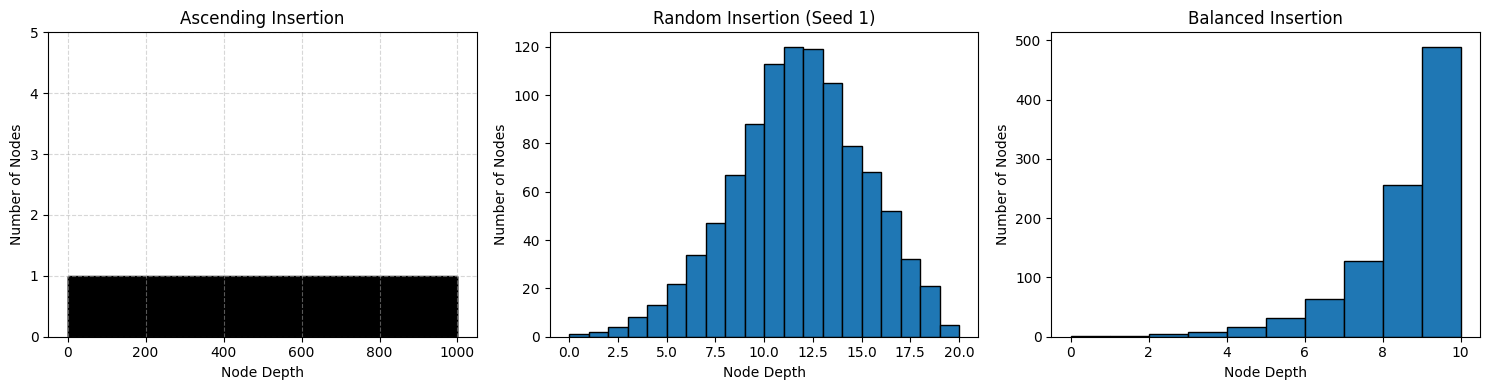

In [95]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(
    ascending_depths,
    bins=range(0, max(ascending_depths) + 2),
    edgecolor="black"
)
axes[0].set_title("Ascending Insertion")
axes[0].set_xlabel("Node Depth")
axes[0].set_ylabel("Number of Nodes")
axes[0].set_ylim(0,5)
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].hist(
    random_depths,
    bins=range(0, max(random_depths) + 2),
    edgecolor="black"
)
axes[1].set_title(f"Random Insertion (Seed {random_seed})")
axes[1].set_xlabel("Node Depth")
axes[1].set_ylabel("Number of Nodes")

axes[2].hist(
    balanced_depths,
    bins=range(0, max(balanced_depths) + 2),
    edgecolor="black"
)
axes[2].set_title("Balanced Insertion")
axes[2].set_xlabel("Node Depth")
axes[2].set_ylabel("Number of Nodes")

plt.tight_layout()
plt.show()